# 04 — Repeated Real-Dataset and Controlled Quadratic Experiments

## Purpose

This is the main experimental notebook. It contains two complementary studies:

1. **Real-dataset study:** compare Batch GD, SGD, Momentum, and Adam on Breast Cancer Wisconsin, Banknote Authentication, and Ionosphere, with original and standardized feature representations.
2. **Controlled quadratic study:** vary the condition number of a two-dimensional quadratic objective while keeping its mathematical form fixed.

The real-data study uses validation-based learning-rate selection, seed-specific stratified train/validation/test splits, validation-based early stopping, and repeated test evaluation. The quadratic study isolates curvature directly and uses a fixed update budget with a sustained-convergence criterion.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_project_root(start=None):
    """Find the repository root from the current Jupyter working directory."""
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src" / "logistic_regression.py").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Open Jupyter from the repository "
        "folder or one of its subfolders."
    )


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import logistic_regression, optimizers

FIGURES_PATH = PROJECT_ROOT / "results" / "figures"
TABLES_PATH = PROJECT_ROOT / "results" / "tables"
FIGURES_PATH.mkdir(parents=True, exist_ok=True)
TABLES_PATH.mkdir(parents=True, exist_ok=True)

import time
from itertools import combinations

import seaborn as sns
from scipy.stats import friedmanchisquare, wilcoxon
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from src.datasets import load_binary_datasets

## Part A — Repeated experiments on real datasets

### A1. Dataset and experimental configuration

Each dataset is evaluated independently. The same stratified split seed is used across optimizers within a seed, so the optimizer comparisons are paired on the same training, validation, and test partitions.

In [2]:
datasets = load_binary_datasets()
DATASET_NAMES = list(datasets)
CONDITIONS = ["original", "standardized"]
OPTIMIZER_NAMES = ["Adam", "Batch GD", "Momentum", "SGD"]

TUNING_CONFIG = {
    "seed": 42,
    "epochs": 100,
    "test_size": 0.20,
    "validation_size": 0.20,
    "l2": 0.0,
}

FINAL_CONFIG = {
    "seeds": list(range(10)),  # disjoint from the tuning seed (42)
    "max_epochs": 300,
    "patience": 20,
    "min_delta": 1e-6,
    "l2": 0.0,
    "test_size": 0.20,
    "validation_size": 0.20,
}

print("Datasets:", DATASET_NAMES)
print("Tuning configuration:", TUNING_CONFIG)
print("Final evaluation configuration:", FINAL_CONFIG)

Datasets: ['Breast Cancer', 'Banknote', 'Ionosphere']
Tuning configuration: {'seed': 42, 'epochs': 100, 'test_size': 0.2, 'validation_size': 0.2, 'l2': 0.0}
Final evaluation configuration: {'seeds': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'max_epochs': 300, 'patience': 20, 'min_delta': 1e-06, 'l2': 0.0, 'test_size': 0.2, 'validation_size': 0.2}


### A2. Learning-rate search space and optimizer factory

The optimizer implementations are imported from the shared `src/optimizers.py` module. Batch GD, Momentum, and Adam use full-batch updates in the real-data comparison; SGD uses a batch size of one.

In [3]:
LEARNING_RATE_GRID = {
    "Batch GD": [1e-5, 1e-4, 1e-3, 1e-2, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0],
    "SGD": [1e-4, 1e-3, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2],
    "Momentum": [1e-5, 1e-4, 1e-3, 1e-2, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0],
    "Adam": [1e-4, 1e-3, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2],
}


def create_optimizer(name, learning_rate):
    if name in ("Batch GD", "SGD"):
        return optimizers.GradientDescent(learning_rate=learning_rate)
    if name == "Momentum":
        return optimizers.Momentum(learning_rate=learning_rate, beta=0.9)
    if name == "Adam":
        return optimizers.Adam(learning_rate=learning_rate)
    raise ValueError(f"Unknown optimizer: {name}")


def get_batch_size(name, n_samples):
    return 1 if name == "SGD" else n_samples

### A3. Tuning split and preprocessing

The tuning split reserves 20% of the observations for testing and 20% for validation, leaving 60% for fitting. The scaler and constant-feature mask are fitted using only the training partition. The test partition is reserved and is not used to select a learning rate.

In [4]:
def split_development_data(X, y, seed, test_size, validation_size):
    """Create stratified train/validation/test partitions with requested proportions."""
    X_dev, X_test, y_dev, y_test = train_test_split(
        X, y, test_size=test_size, random_state=seed, stratify=y
    )
    validation_fraction_of_development = validation_size / (1.0 - test_size)
    X_train, X_val, y_train, y_val = train_test_split(
        X_dev,
        y_dev,
        test_size=validation_fraction_of_development,
        random_state=seed,
        stratify=y_dev,
    )
    return X_train, X_val, X_test, y_train, y_val, y_test


def prepare_partition(X, y, condition, seed, test_size, validation_size):
    X_train, X_val, X_test, y_train, y_val, y_test = split_development_data(
        X, y, seed, test_size, validation_size
    )

    # Identify constants from the training partition only.
    keep_mask = np.std(X_train, axis=0) > 1e-10
    X_train = X_train[:, keep_mask]
    X_val = X_val[:, keep_mask]
    X_test = X_test[:, keep_mask]

    if condition == "standardized":
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_val = scaler.transform(X_val)
        X_test = scaler.transform(X_test)
    elif condition != "original":
        raise ValueError("condition must be 'original' or 'standardized'.")

    return {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test,
        "feature_mask": keep_mask,
    }

### A4. Validation-based learning-rate tuning

Each learning rate is trained for the same fixed number of epochs. The learning rate with the lowest validation log loss is selected. To reduce noise in the grid comparison, every candidate within a tuning configuration uses the same deterministic shuffle seed. The tuning seed (42) is not included among the final evaluation seeds (0–9).

In [5]:
def tune_optimizer(X_train, y_train, X_val, y_val, optimizer_name, learning_rates):
    records = []
    batch_size = get_batch_size(optimizer_name, len(y_train))

    for learning_rate in learning_rates:
        try:
            model = logistic_regression.LogisticRegression(l2=TUNING_CONFIG["l2"])
            model.fit(
                X_train,
                y_train,
                optimizer=create_optimizer(optimizer_name, learning_rate),
                epochs=TUNING_CONFIG["epochs"],
                batch_size=batch_size,
                shuffle=True,
                random_state=TUNING_CONFIG["seed"],
            )
            probabilities = model.predict_proba(X_val)
            if not np.all(np.isfinite(probabilities)):
                raise FloatingPointError("Non-finite validation probabilities.")
            validation_loss = log_loss(y_val, probabilities, labels=[0, 1])
            if not np.isfinite(validation_loss):
                raise FloatingPointError("Non-finite validation loss.")
            status = "Valid"
        except (FloatingPointError, ValueError, OverflowError):
            validation_loss = np.inf
            status = "Diverged or invalid"

        records.append(
            {
                "Optimizer": optimizer_name,
                "Learning Rate": float(learning_rate),
                "Validation Log Loss": float(validation_loss),
                "Status": status,
            }
        )

    tuning_df = pd.DataFrame(records)
    valid = tuning_df[tuning_df["Status"] == "Valid"]
    if valid.empty:
        raise RuntimeError(f"No valid learning rate found for {optimizer_name}.")
    best = valid.loc[valid["Validation Log Loss"].idxmin()]
    return best, tuning_df


tuning_records = []
selected_hyperparameters = {}

for dataset_name, (X_data, y_data) in datasets.items():
    for condition in CONDITIONS:
        tuning_data = prepare_partition(
            X_data,
            y_data,
            condition,
            seed=TUNING_CONFIG["seed"],
            test_size=TUNING_CONFIG["test_size"],
            validation_size=TUNING_CONFIG["validation_size"],
        )
        for optimizer_name in OPTIMIZER_NAMES:
            best, candidate_results = tune_optimizer(
                tuning_data["X_train"],
                tuning_data["y_train"],
                tuning_data["X_val"],
                tuning_data["y_val"],
                optimizer_name,
                LEARNING_RATE_GRID[optimizer_name],
            )
            candidate_results["Dataset"] = dataset_name
            candidate_results["Condition"] = condition
            tuning_records.append(candidate_results)
            selected_hyperparameters[(dataset_name, condition, optimizer_name)] = float(
                best["Learning Rate"]
            )
            print(
                f"{dataset_name:14s} | {condition:13s} | {optimizer_name:10s} "
                f"| LR={best['Learning Rate']:.6g} "
                f"| validation log loss={best['Validation Log Loss']:.5f}"
            )

tuning_results_df = pd.concat(tuning_records, ignore_index=True)

selected_rows = []
for (dataset_name, condition, optimizer_name), learning_rate in selected_hyperparameters.items():
    grid = LEARNING_RATE_GRID[optimizer_name]
    at_min = np.isclose(learning_rate, min(grid))
    at_max = np.isclose(learning_rate, max(grid))
    selected_rows.append(
        {
            "Dataset": dataset_name,
            "Condition": condition,
            "Optimizer": optimizer_name,
            "Selected Learning Rate": learning_rate,
            "At Search Boundary": bool(at_min or at_max),
            "Boundary": "Minimum" if at_min else ("Maximum" if at_max else "Interior"),
        }
    )
selected_hyperparameters_df = pd.DataFrame(selected_rows)
display(selected_hyperparameters_df.sort_values(["Dataset", "Condition", "Optimizer"]))

Breast Cancer  | original      | Adam       | LR=0.01 | validation log loss=0.18684
Breast Cancer  | original      | Batch GD   | LR=1e-05 | validation log loss=0.51229
Breast Cancer  | original      | Momentum   | LR=0.0001 | validation log loss=0.27878
Breast Cancer  | original      | SGD        | LR=0.0001 | validation log loss=2.88649
Breast Cancer  | standardized  | Adam       | LR=0.05 | validation log loss=0.06088
Breast Cancer  | standardized  | Batch GD   | LR=2 | validation log loss=0.05795
Breast Cancer  | standardized  | Momentum   | LR=1 | validation log loss=0.06242
Breast Cancer  | standardized  | SGD        | LR=0.01 | validation log loss=0.05511
Banknote       | original      | Adam       | LR=0.2 | validation log loss=0.01434
Banknote       | original      | Batch GD   | LR=2 | validation log loss=0.01689
Banknote       | original      | Momentum   | LR=2 | validation log loss=0.01488
Banknote       | original      | SGD        | LR=0.02 | validation log loss=0.01114


,Dataset,Condition,Optimizer,Selected Learning Rate,At Search Boundary,Boundary
8,Banknote,original,Adam,0.20000,True,Maximum
9,Banknote,original,Batch GD,2.00000,True,Maximum
10,Banknote,original,Momentum,2.00000,True,Maximum
11,Banknote,original,SGD,0.02000,False,Interior
12,Banknote,standardized,Adam,0.20000,True,Maximum
13,Banknote,standardized,Batch GD,2.00000,True,Maximum
14,Banknote,standardized,Momentum,2.00000,True,Maximum
15,Banknote,standardized,SGD,0.20000,True,Maximum
0,Breast Cancer,original,Adam,0.01000,False,Interior
1,Breast Cancer,original,Batch GD,0.00001,True,Minimum


In [6]:
tuning_results_df.to_csv(TABLES_PATH / "hyperparameter_search.csv", index=False)
selected_hyperparameters_df.to_csv(
    TABLES_PATH / "selected_hyperparameters.csv", index=False
)
print("Saved learning-rate search results and selected rates.")

Saved learning-rate search results and selected rates.


### A5. Final repeated evaluation protocol

For each dataset, feature condition, and evaluation seed, a new stratified train/validation/test split is generated. The selected learning rate is held fixed. Early stopping monitors validation log loss only; the test set is evaluated after restoring the parameters from the best validation epoch.

The design contains (3 datasets) x (2 feature conditions) x (4 optimizers) x (10 seeds) = **240 runs**.

In [7]:
def train_with_early_stopping(
    X_train, y_train, X_val, y_val, optimizer, batch_size,
    max_epochs, patience, min_delta, l2, seed,
):
    rng = np.random.default_rng(seed)
    X_train_bias = logistic_regression.add_intercept(X_train)
    X_val_bias = logistic_regression.add_intercept(X_val)
    n_samples, n_parameters = X_train_bias.shape

    theta = np.zeros(n_parameters, dtype=float)
    optimizer.reset(n_parameters)
    best_theta = theta.copy()
    best_validation_loss = np.inf
    best_training_loss = np.inf
    best_epoch = 0
    epochs_without_improvement = 0
    training_loss_history = []
    validation_loss_history = []

    for epoch in range(max_epochs):
        indices = rng.permutation(n_samples)
        X_epoch = X_train_bias[indices]
        y_epoch = y_train[indices]

        for start in range(0, n_samples, batch_size):
            end = min(start + batch_size, n_samples)
            gradient = logistic_regression.compute_gradient(
                X_epoch[start:end], y_epoch[start:end], theta, l2=l2
            )
            theta = optimizer.step(theta, gradient)
            if not np.all(np.isfinite(theta)):
                raise FloatingPointError("Non-finite model parameters encountered.")

        training_loss = logistic_regression.binary_cross_entropy(
            X_train_bias, y_train, theta, l2=l2
        )
        validation_probabilities = logistic_regression.sigmoid(X_val_bias @ theta)
        validation_loss = log_loss(
            y_val, validation_probabilities, labels=[0, 1]
        )
        if not np.isfinite(training_loss) or not np.isfinite(validation_loss):
            raise FloatingPointError("Non-finite loss encountered.")

        training_loss_history.append(training_loss)
        validation_loss_history.append(validation_loss)

        if validation_loss < best_validation_loss - min_delta:
            best_validation_loss = validation_loss
            best_training_loss = training_loss
            best_theta = theta.copy()
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            break

    model = logistic_regression.LogisticRegression(l2=l2)
    model.theta = best_theta
    model.n_features_in_ = X_train.shape[1]
    model.loss_history = training_loss_history[:best_epoch]

    return model, {
        "best_epoch": best_epoch,
        "epochs_run": len(training_loss_history),
        "best_validation_loss": best_validation_loss,
        "best_training_loss": best_training_loss,
        "training_loss_history": training_loss_history,
        "validation_loss_history": validation_loss_history,
    }


def run_final_experiments():
    records = []
    expected_runs = (
        len(datasets) * len(CONDITIONS) * len(OPTIMIZER_NAMES) *
        len(FINAL_CONFIG["seeds"])
    )

    for dataset_name, (X_data, y_data) in datasets.items():
        for condition in CONDITIONS:
            for seed in FINAL_CONFIG["seeds"]:
                data = prepare_partition(
                    X_data,
                    y_data,
                    condition,
                    seed=seed,
                    test_size=FINAL_CONFIG["test_size"],
                    validation_size=FINAL_CONFIG["validation_size"],
                )
                X_train, X_val, X_test = data["X_train"], data["X_val"], data["X_test"]
                y_train, y_val, y_test = data["y_train"], data["y_val"], data["y_test"]

                for optimizer_name in OPTIMIZER_NAMES:
                    learning_rate = selected_hyperparameters[
                        (dataset_name, condition, optimizer_name)
                    ]
                    batch_size = get_batch_size(optimizer_name, len(y_train))
                    start_time = time.perf_counter()
                    model, info = train_with_early_stopping(
                        X_train,
                        y_train,
                        X_val,
                        y_val,
                        optimizer=create_optimizer(optimizer_name, learning_rate),
                        batch_size=batch_size,
                        max_epochs=FINAL_CONFIG["max_epochs"],
                        patience=FINAL_CONFIG["patience"],
                        min_delta=FINAL_CONFIG["min_delta"],
                        l2=FINAL_CONFIG["l2"],
                        seed=seed,
                    )
                    elapsed = time.perf_counter() - start_time

                    test_probabilities = model.predict_proba(X_test)
                    test_predictions = model.predict(X_test)
                    updates_per_epoch = int(np.ceil(len(y_train) / batch_size))

                    records.append(
                        {
                            "Dataset": dataset_name,
                            "Condition": condition,
                            "Optimizer": optimizer_name,
                            "Seed": seed,
                            "Learning Rate": learning_rate,
                            "Best Epoch": info["best_epoch"],
                            "Epochs Run": info["epochs_run"],
                            "Parameter Updates": updates_per_epoch * info["epochs_run"],
                            "Training Loss": info["best_training_loss"],
                            "Validation Log Loss": info["best_validation_loss"],
                            "Test Accuracy": accuracy_score(y_test, test_predictions),
                            "Test Log Loss": log_loss(y_test, test_probabilities, labels=[0, 1]),
                            "Training Time (s)": elapsed,
                        }
                    )

    results = pd.DataFrame(records)
    if len(results) != expected_runs:
        raise AssertionError(f"Expected {expected_runs} runs, obtained {len(results)}.")
    return results


final_results = run_final_experiments()
final_results.to_csv(TABLES_PATH / "final_repeated_experiments.csv", index=False)
print("Completed real-dataset runs:", len(final_results))
display(final_results.head())

Completed real-dataset runs: 240


,Dataset,Condition,Optimizer,Seed,Learning Rate,Best Epoch,Epochs Run,Parameter Updates,Training Loss,Validation Log Loss,Test Accuracy,Test Log Loss,Training Time (s)
0,Breast Cancer,original,Adam,0,0.01000,300,300,300,0.147524,0.130031,0.921053,0.170667,1.462054
1,Breast Cancer,original,Batch GD,0,0.00001,1,21,21,0.764815,0.758674,0.368421,0.781398,0.125473
2,Breast Cancer,original,Momentum,0,0.00010,300,300,300,0.231144,0.178702,0.912281,0.220469,1.003487
3,Breast Cancer,original,SGD,0,0.00010,2,22,7502,1.425709,0.962086,0.894737,1.312121,1.317235
4,Breast Cancer,original,Adam,1,0.01000,300,300,300,0.154922,0.138666,0.964912,0.115563,0.992005


### A6. Validate run coverage and summarize performance

Every dataset/condition/optimizer combination should contain ten evaluation seeds, with one record per seed. Training time is included as a descriptive measurement; it can vary with hardware and system load and should not be interpreted as a hardware-independent optimizer property.

In [8]:
expected_per_configuration = len(FINAL_CONFIG["seeds"])
run_counts = final_results.groupby(
    ["Dataset", "Condition", "Optimizer"]
).size()
assert (run_counts == expected_per_configuration).all()
assert not final_results.duplicated(
    ["Dataset", "Condition", "Optimizer", "Seed"]
).any()

metric_columns = [
    "Learning Rate", "Best Epoch", "Epochs Run", "Parameter Updates",
    "Training Loss", "Validation Log Loss", "Test Accuracy",
    "Test Log Loss", "Training Time (s)",
]
assert final_results[metric_columns].notna().all().all()
assert np.isfinite(final_results[metric_columns].to_numpy(dtype=float)).all()

print("Run matrix:")
display(run_counts.unstack("Optimizer"))
summary = (
    final_results.groupby(["Dataset", "Condition", "Optimizer"])[
        ["Test Accuracy", "Test Log Loss", "Training Loss", "Best Epoch", "Training Time (s)"]
    ]
    .agg(["mean", "std"])
    .round(4)
)
display(summary)
summary.to_csv(TABLES_PATH / "real_dataset_descriptive_summary.csv")

Run matrix:


Optimizer                   Adam  Batch GD  Momentum  SGD
Dataset       Condition                                  
Banknote      original        10        10        10   10
              standardized    10        10        10   10
Breast Cancer original        10        10        10   10
              standardized    10        10        10   10
Ionosphere    original        10        10        10   10
              standardized    10        10        10   10

Test Accuracy         Test Log Loss  \
                                              mean     std          mean   
Dataset       Condition    Optimizer                                       
Banknote      original     Adam             0.9898  0.0070        0.0263   
                           Batch GD         0.9895  0.0065        0.0251   
                           Momentum         0.9895  0.0065        0.0247   
                           SGD              0.9895  0.0074        0.0246   
              standardized Adam             0.9891  0.0084        0.0301   
                           Batch GD         0.9825  0.0082        0.0419   
                           Momentum         0.9825  0.0082        0.0405   
                           SGD              0.9895  0.0093        0.0246   
Breast Cancer original     Adam             0.9404  0.0237        0.1615   
                           Batch GD         0.5272  0.2557        0.6270   
                           Momentum         0.9211  0.0180        0.2069   
                           SGD              0.9096  0.0144        1.4125   
              standardized Adam             0.9789  0.0094        0.0631   
                           Batch GD         0.9807  0.0115        0.0565   
                           Momentum         0.9781  0.0085        0.0576   
                           SGD              0.9807  0.0108        0.0576   
Ionosphere    original     Adam             0.8282  0.0643        0.4472   
                           Batch GD         0.8634  0.0404        0.3805   
                           Momentum         0.8577  0.0372        0.3868   
                           SGD              0.8592  0.0358        0.3759   
              standardized Adam             0.8746  0.0354        0.3436   
                           Batch GD         0.8873  0.0282        0.3153   
                           Momentum         0.8831  0.0305        0.3143   
                           SGD              0.8873  0.0282        0.3159   

                                             Training Loss         Best Epoch  \
                                         std          mean     std       mean   
Dataset       Condition    Optimizer                                            
Banknote      original     Adam       0.0105        0.0262  0.0060      197.1   
                           Batch GD   0.0096        0.0229  0.0025      271.9   
                           Momentum   0.0091        0.0223  0.0029      220.9   
                           SGD        0.0100        0.0222  0.0036      107.1   
              standardized Adam       0.0099        0.0291  0.0026      300.0   
                           Batch GD   0.0121        0.0410  0.0030      300.0   
                           Momentum   0.0120        0.0396  0.0030      300.0   
                           SGD        0.0115        0.0224  0.0033       89.9   
Breast Cancer original     Adam       0.0438        0.1691  0.0441      243.5   
                           Batch GD   0.2049        0.6264  0.2014       90.7   
                           Momentum   0.0257        0.2211  0.0131      300.0   
                           SGD        0.4696        1.6498  0.4526        4.0   
              standardized Adam       0.0230        0.0606  0.0093      108.5   
                           Batch GD   0.0182        0.0594  0.0153      100.9   
                           Momentum   0.0163        0.0668  0.0109       81.0   
                           SGD        0.0179        0.0558  0.0067       73.3   
Ionosphere    original     Adam       0.1195        0.3023  0.1118       61.4   
                           Batch GD   0.0689        0.2536  0.0509       68.4   
                           Momentum   0.0646        0.2668  0.0596       60.1   
                           SGD        0.0638        0.2547  0.0470       61.3   
              standardized Adam       0.0676        0.2499  0.0473       46.2   
                           Batch GD   0.

### A7. Paired statistical analysis

The four optimizers are compared within each dataset, feature condition, and metric using the ten matched evaluation seeds.

- **Friedman test:** omnibus non-parametric test across the four related optimizer samples.
- **Wilcoxon signed-rank test:** paired post-hoc comparisons between optimizer pairs.
- **Holm correction:** applied within each set of six pairwise tests and separately across all pairwise tests.
- **Effect size:** paired rank-biserial correlation; positive values indicate that optimizer A tends to have larger metric values than optimizer B.

With ten seeds, statistical power is limited. The p-values should be interpreted alongside descriptive differences and effect sizes.

In [9]:
def holm_correction(p_values):
    """Holm-Bonferroni adjusted p-values, returned in original order."""
    p_values = np.asarray(p_values, dtype=float)
    if p_values.ndim != 1 or not np.all(np.isfinite(p_values)):
        raise ValueError("p_values must be a finite one-dimensional array.")
    n_tests = len(p_values)
    order = np.argsort(p_values)
    adjusted = np.empty(n_tests, dtype=float)
    running_max = 0.0
    for rank, original_index in enumerate(order):
        corrected = (n_tests - rank) * p_values[original_index]
        running_max = max(running_max, corrected)
        adjusted[original_index] = min(running_max, 1.0)
    return adjusted


def paired_rank_biserial(a, b):
    """Paired rank-biserial correlation; positive means A has larger values."""
    differences = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    differences = differences[differences != 0]
    if differences.size == 0:
        return 0.0
    ranks = pd.Series(np.abs(differences)).rank(method="average").to_numpy()
    positive = ranks[differences > 0].sum()
    negative = ranks[differences < 0].sum()
    denominator = positive + negative
    return float((positive - negative) / denominator) if denominator else 0.0


friedman_records = []
pairwise_records = []
for dataset_name in DATASET_NAMES:
    for condition in CONDITIONS:
        subset = final_results[
            (final_results["Dataset"] == dataset_name) &
            (final_results["Condition"] == condition)
        ]
        for metric in ["Test Log Loss", "Test Accuracy"]:
            pivot = subset.pivot(index="Seed", columns="Optimizer", values=metric)
            pivot = pivot.reindex(columns=OPTIMIZER_NAMES).sort_index()
            if pivot.shape != (len(FINAL_CONFIG["seeds"]), len(OPTIMIZER_NAMES)) or pivot.isna().any().any():
                raise AssertionError("Incomplete paired data for statistical testing.")

            statistic, p_value = friedmanchisquare(
                *[pivot[name].to_numpy() for name in OPTIMIZER_NAMES]
            )
            friedman_records.append(
                {
                    "Dataset": dataset_name,
                    "Condition": condition,
                    "Metric": metric,
                    "Friedman Statistic": statistic,
                    "Raw P-value": p_value,
                }
            )

            comparisons = []
            for optimizer_a, optimizer_b in combinations(OPTIMIZER_NAMES, 2):
                values_a = pivot[optimizer_a].to_numpy()
                values_b = pivot[optimizer_b].to_numpy()
                if np.allclose(values_a, values_b):
                    test_statistic, raw_p = 0.0, 1.0
                else:
                    test_statistic, raw_p = wilcoxon(
                        values_a, values_b, alternative="two-sided", method="auto"
                    )
                comparisons.append(
                    {
                        "Dataset": dataset_name,
                        "Condition": condition,
                        "Metric": metric,
                        "Optimizer A": optimizer_a,
                        "Optimizer B": optimizer_b,
                        "Wilcoxon Statistic": test_statistic,
                        "Raw P-value": raw_p,
                        "Mean Difference (A - B)": float(np.mean(values_a - values_b)),
                        "Rank-Biserial Effect": paired_rank_biserial(values_a, values_b),
                    }
                )
            within_group_adjusted = holm_correction(
                [row["Raw P-value"] for row in comparisons]
            )
            for row, adjusted in zip(comparisons, within_group_adjusted):
                row["Within-Group Holm P-value"] = adjusted
                row["Significant Within Group"] = bool(adjusted < 0.05)
                pairwise_records.append(row)

friedman_df = pd.DataFrame(friedman_records)
friedman_df["Global Holm P-value"] = holm_correction(friedman_df["Raw P-value"])
friedman_df["Significant After Global Holm"] = friedman_df["Global Holm P-value"] < 0.05

pairwise_df = pd.DataFrame(pairwise_records)
pairwise_df["Global Holm P-value"] = holm_correction(pairwise_df["Raw P-value"])
pairwise_df["Significant After Global Holm"] = pairwise_df["Global Holm P-value"] < 0.05

display(friedman_df.round(6))
display(pairwise_df.round(6))

friedman_df.to_csv(TABLES_PATH / "friedman_tests.csv", index=False)
pairwise_df.to_csv(TABLES_PATH / "pairwise_wilcoxon_tests.csv", index=False)

,Dataset,Condition,Metric,Friedman Statistic,Raw P-value,Global Holm P-value,Significant After Global Holm
0,Breast Cancer,original,Test Log Loss,28.080000,0.000003,0.000038,True
1,Breast Cancer,original,Test Accuracy,22.831579,0.000044,0.000394,True
2,Breast Cancer,standardized,Test Log Loss,1.800000,0.614935,1.000000,False
3,Breast Cancer,standardized,Test Accuracy,1.500000,0.682270,1.000000,False
4,Banknote,original,Test Log Loss,1.080000,0.781904,1.000000,False
5,Banknote,original,Test Accuracy,0.600000,0.896432,1.000000,False
6,Banknote,standardized,Test Log Loss,30.000000,0.000001,0.000017,True
7,Banknote,standardized,Test Accuracy,26.414634,0.000008,0.000078,True
8,Ionosphere,original,Test Log Loss,12.960000,0.004724,0.033067,True
9,Ionosphere,original,Test Accuracy,18.440000,0.000357,0.002855,True


,Dataset,Condition,Metric,Optimizer A,Optimizer B,Wilcoxon Statistic,Raw P-value,Mean Difference (A - B),Rank-Biserial Effect,Within-Group Holm P-value,Significant Within Group,Global Holm P-value,Significant After Global Holm
0,Breast Cancer,original,Test Log Loss,Adam,Batch GD,0.0,0.001953,-0.465496,-1.000000,0.011719,True,0.140625,False
1,Breast Cancer,original,Test Log Loss,Adam,Momentum,3.0,0.009766,-0.045380,-0.890909,0.011719,True,0.507812,False
2,Breast Cancer,original,Test Log Loss,Adam,SGD,0.0,0.001953,-1.250918,-1.000000,0.011719,True,0.140625,False
3,Breast Cancer,original,Test Log Loss,Batch GD,Momentum,0.0,0.001953,0.420116,1.000000,0.011719,True,0.140625,False
4,Breast Cancer,original,Test Log Loss,Batch GD,SGD,0.0,0.001953,-0.785422,-1.000000,0.011719,True,0.140625,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,Ionosphere,standardized,Test Accuracy,Adam,Momentum,4.0,0.250000,-0.008451,-0.619048,1.000000,False,1.000000,False
68,Ionosphere,standardized,Test Accuracy,Adam,SGD,2.0,0.125000,-0.012676,-0.809524,0.750000,False,1.000000,False
69,Ionosphere,standardized,Test Accuracy,Batch GD,Momentum,0.0,0.250000,0.004225,1.000000,1.000000,False,1.000000,False
70,Ionosphere,standardized,Test Accuracy,Batch GD,SGD,0.0,1.000000,0.000000,0.000000,1.000000,False,1.000000,False


### A8. Performance visualizations

Bars show the mean across evaluation seeds; error bars show one standard deviation, not a confidence interval. Original and standardized feature conditions are displayed separately to avoid visually conflating the ablation conditions.

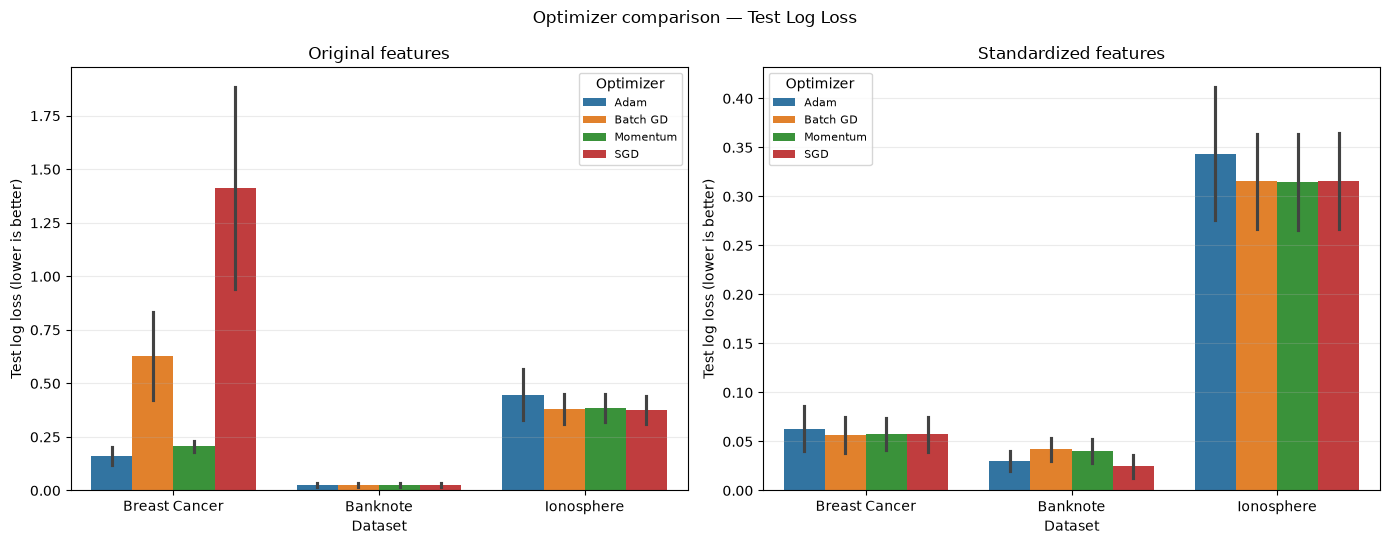

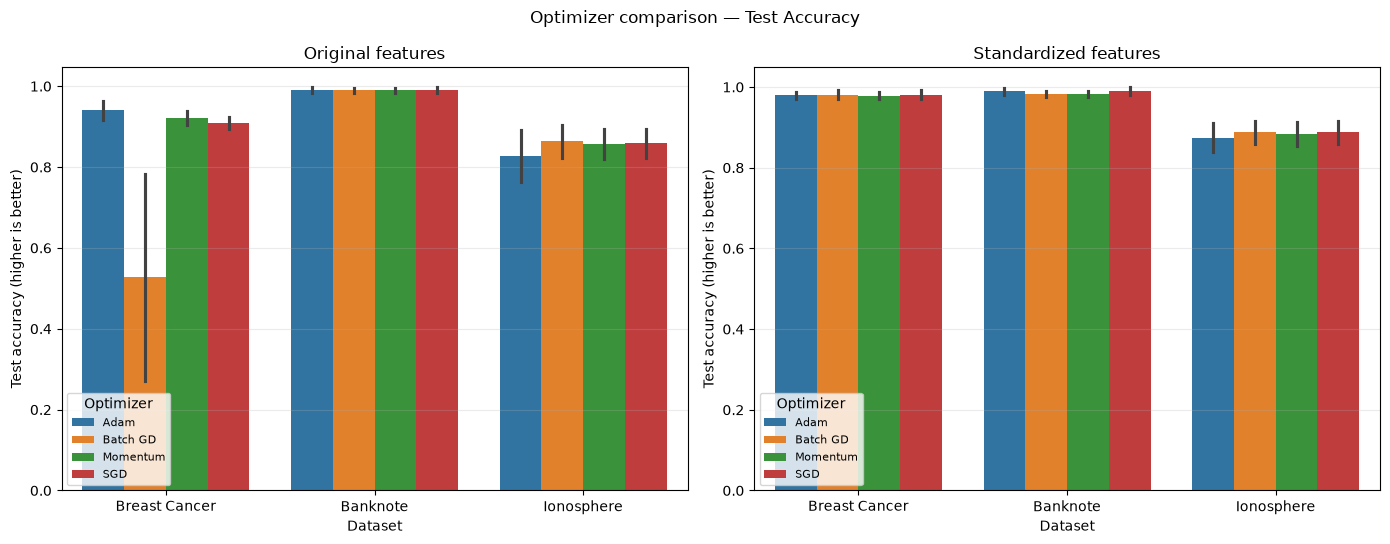

In [10]:
for metric, ylabel, filename in [
    ("Test Log Loss", "Test log loss (lower is better)", "real_data_test_log_loss.png"),
    ("Test Accuracy", "Test accuracy (higher is better)", "real_data_test_accuracy.png"),
]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=False)
    for ax, condition in zip(axes, CONDITIONS):
        subset = final_results[final_results["Condition"] == condition]
        sns.barplot(
            data=subset,
            x="Dataset",
            y=metric,
            hue="Optimizer",
            errorbar="sd",
            ax=ax,
        )
        ax.set_title(f"{condition.capitalize()} features")
        ax.set_xlabel("Dataset")
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", alpha=0.25)
        ax.legend(title="Optimizer", fontsize=8)
    fig.suptitle(f"Optimizer comparison — {metric}")
    fig.tight_layout()
    fig.savefig(FIGURES_PATH / filename, dpi=300, bbox_inches="tight")
    plt.show()

### A9. Real-dataset interpretation notes

Report means and standard deviations together with the omnibus and pairwise tests. Within-group and global Holm-adjusted pairwise results are kept distinct: the latter applies the more conservative correction across the entire family of pairwise comparisons.

This is a repeated-split comparison on each dataset. It is not a transfer-learning experiment in which a model trained on one dataset is tested on another; rather, it checks whether the optimizer/scaling patterns are observed across multiple independent datasets.

---

## Part B — Controlled quadratic conditioning experiment

### B1. Objective and mathematical setup

We minimize

$$
 f(\theta)=\frac{1}{2}\theta^T H\theta,
 \qquad H=\begin{bmatrix}1&0\\0&\kappa\end{bmatrix}.
$$

The eigenvalues are \(1\) and (κ), so the Hessian condition number is (κ). The minimizer is _θ*_=(0,0), with minimum loss zero. We examine (κ) in {1,10,100,1000,10000}.

For SGD, one coordinate is sampled uniformly at each update and its gradient component is multiplied by the dimension. This is an unbiased stochastic coordinate-gradient estimator; it is not mini-batch sampling from the real datasets.

Momentum uses the project's normalized exponential moving average of gradients, not the unnormalized heavy-ball convention. Learning-rate grids are therefore defined for the actual update implemented in `src/optimizers.py`.

In [11]:
QUADRATIC_CONFIG = {
    "condition_numbers": [1, 10, 100, 1000, 10000],
    "tuning_seed": 42,
    "evaluation_seeds": list(range(10)),
    "max_updates": 5000,
    "convergence_threshold": 1e-8,
    "convergence_window": 10,
    "momentum_beta": 0.9,
}
QUADRATIC_OPTIMIZERS = ["Adam", "Batch GD", "Momentum", "SGD"]


def quadratic_loss(theta, H):
    with np.errstate(over="ignore", invalid="ignore"):
        value = 0.5 * theta.T @ H @ theta
    return float(value) if np.isfinite(value) else np.inf


def quadratic_gradient(theta, H):
    return H @ theta


def create_hessian(condition_number):
    if condition_number < 1:
        raise ValueError("condition_number must be at least 1.")
    return np.diag([1.0, float(condition_number)])


def finite_difference_gradient(function, point, epsilon=1e-6):
    point = np.asarray(point, dtype=float)
    result = np.zeros_like(point)
    for index in range(point.size):
        plus, minus = point.copy(), point.copy()
        plus[index] += epsilon
        minus[index] -= epsilon
        result[index] = (function(plus) - function(minus)) / (2 * epsilon)
    return result


check_theta = np.array([5.0, 5.0])
check_H = create_hessian(100)
analytic = quadratic_gradient(check_theta, check_H)
numerical = finite_difference_gradient(
    lambda candidate: quadratic_loss(candidate, check_H), check_theta
)
assert np.allclose(analytic, numerical, atol=1e-5)
for kappa in QUADRATIC_CONFIG["condition_numbers"]:
    H = create_hessian(kappa)
    assert np.isclose(np.linalg.cond(H), kappa)
print("Quadratic gradient and Hessian-condition checks passed.")
print("Analytical gradient:", analytic)
print("Finite-difference gradient:", numerical)

Quadratic gradient and Hessian-condition checks passed.
Analytical gradient: [  5. 500.]
Finite-difference gradient: [  4.99999999 500.0000001 ]


### B2. Optimizer runner and convergence criterion

A run is considered converged when the objective remains at or below (10⁻⁸) for ten consecutive updates. Every run is limited to 5,000 updates. A run that reaches the budget without meeting the threshold is **not converged**; if all values remain finite, it is still considered stable.

Equal update budgets do not imply equal arithmetic cost: full-gradient methods evaluate both coordinates at every update, while SGD samples one coordinate. Report this distinction when interpreting the results.

In [12]:
def stochastic_quadratic_gradient(theta, H, rng):
    dimension = len(theta)
    coordinate = rng.integers(dimension)
    gradient = np.zeros_like(theta, dtype=float)
    gradient[coordinate] = dimension * H[coordinate, coordinate] * theta[coordinate]
    return gradient


def create_quadratic_optimizer(name, learning_rate):
    if name in ("Batch GD", "SGD"):
        return optimizers.GradientDescent(learning_rate)
    if name == "Momentum":
        return optimizers.Momentum(
            learning_rate, beta=QUADRATIC_CONFIG["momentum_beta"]
        )
    if name == "Adam":
        return optimizers.Adam(learning_rate)
    raise ValueError(f"Unknown optimizer: {name}")


def run_quadratic_optimizer(
    H, optimizer_name, learning_rate, seed,
    initial_theta=None,
):
    rng = np.random.default_rng(seed)
    initial_rng = np.random.default_rng(seed + 1_000_003)
    theta = (
        initial_rng.uniform(-5.0, 5.0, size=2)
        if initial_theta is None
        else np.asarray(initial_theta, dtype=float).copy()
    )
    initial_theta_used = theta.copy()
    if theta.shape != (2,) or not np.all(np.isfinite(theta)):
        raise ValueError("initial_theta must be a finite two-dimensional vector.")

    optimizer = create_quadratic_optimizer(optimizer_name, learning_rate)
    optimizer.reset(len(theta))
    loss_history = [quadratic_loss(theta, H)]
    stable = bool(np.isfinite(loss_history[0]))
    consecutive_below = 0
    convergence_update = None

    for update in range(1, QUADRATIC_CONFIG["max_updates"] + 1):
        if not stable:
            break
        if optimizer_name == "SGD":
            gradient = stochastic_quadratic_gradient(theta, H, rng)
        else:
            gradient = quadratic_gradient(theta, H)

        theta = optimizer.step(theta, gradient)
        if not np.all(np.isfinite(theta)):
            stable = False
            break
        current_loss = quadratic_loss(theta, H)
        if not np.isfinite(current_loss):
            stable = False
            break
        loss_history.append(current_loss)

        if current_loss <= QUADRATIC_CONFIG["convergence_threshold"]:
            consecutive_below += 1
        else:
            consecutive_below = 0
        if consecutive_below >= QUADRATIC_CONFIG["convergence_window"]:
            convergence_update = update
            break

    return {
        "initial_theta": initial_theta_used,
        "final_theta": theta,
        "final_loss": loss_history[-1],
        "loss_history": loss_history,
        "parameter_updates": len(loss_history) - 1,
        "convergence_update": convergence_update,
        "converged": convergence_update is not None,
        "stable": stable,
    }

### B3. Learning-rate tuning

Each optimizer and condition number has its own candidate grid. The tuning seed (42) is separate from the ten evaluation seeds. If at least one stable candidate converges, selection minimizes the update count to sustained convergence, breaking ties by final loss. If no candidate converges, selection uses the stable candidate with the lowest final loss. Such a selected configuration must be reported as **not converged during tuning**.

A rate selected at the minimum or maximum of a grid indicates a boundary choice. The reported performance is therefore the best result among the tested candidates; it does not prove that the global best learning rate was found.

In [13]:
def quadratic_learning_rate_grid(kappa):
    beta = QUADRATIC_CONFIG["momentum_beta"]
    batch_max = 1.8 / kappa
    sgd_max = 0.9 / kappa
    momentum_max = 0.9 * 2 * (1 + beta) / ((1 - beta) * kappa)
    grids = {
        "Batch GD": batch_max * np.array([0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 0.85, 1.0]),
        "SGD": sgd_max * np.array([0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0]),
        "Momentum": momentum_max * np.array([0.02, 0.05, 0.1, 0.2, 0.35, 0.5, 0.7, 1.0]),
        "Adam": np.array([0.001, 0.003, 0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0]),
    }
    return {
        name: np.unique(np.round(values, 12)).tolist()
        for name, values in grids.items()
    }


def tune_quadratic_optimizer(H, optimizer_name, learning_rates):
    records = []
    for learning_rate in learning_rates:
        result = run_quadratic_optimizer(
            H, optimizer_name, learning_rate,
            seed=QUADRATIC_CONFIG["tuning_seed"],
        )
        records.append(
            {
                "Optimizer": optimizer_name,
                "Learning Rate": learning_rate,
                "Final Loss": result["final_loss"],
                "Converged": result["converged"],
                "Stable": result["stable"],
                "Convergence Update": result["convergence_update"],
                "Parameter Updates": result["parameter_updates"],
            }
        )
    candidates = pd.DataFrame(records)
    stable = candidates[candidates["Stable"]]
    if stable.empty:
        raise RuntimeError(f"No stable candidate found for {optimizer_name}.")
    converged = stable[stable["Converged"]]
    if not converged.empty:
        best = converged.sort_values(
            ["Convergence Update", "Final Loss"]
        ).iloc[0]
    else:
        best = stable.sort_values("Final Loss").iloc[0]
    return candidates, best


quadratic_tuning_frames = []
quadratic_selected = {}
for kappa in QUADRATIC_CONFIG["condition_numbers"]:
    H = create_hessian(kappa)
    grids = quadratic_learning_rate_grid(kappa)
    for optimizer_name in QUADRATIC_OPTIMIZERS:
        candidates, best = tune_quadratic_optimizer(
            H, optimizer_name, grids[optimizer_name]
        )
        candidates["Condition Number"] = kappa
        quadratic_tuning_frames.append(candidates)
        quadratic_selected[(kappa, optimizer_name)] = best.to_dict()

quadratic_tuning_df = pd.concat(quadratic_tuning_frames, ignore_index=True)
quadratic_selected_rows = []
for (kappa, optimizer_name), best in quadratic_selected.items():
    grid = quadratic_learning_rate_grid(kappa)[optimizer_name]
    rate = float(best["Learning Rate"])
    at_min = bool(np.isclose(rate, min(grid)))
    at_max = bool(np.isclose(rate, max(grid)))
    quadratic_selected_rows.append(
        {
            "Condition Number": kappa,
            "Optimizer": optimizer_name,
            "Selected Learning Rate": rate,
            "Tuning Converged": bool(best["Converged"]),
            "Tuning Final Loss": float(best["Final Loss"]),
            "At Search Boundary": at_min or at_max,
            "Boundary": "Minimum" if at_min else ("Maximum" if at_max else "Interior"),
        }
    )
quadratic_selected_df = pd.DataFrame(quadratic_selected_rows)

display(quadratic_selected_df)
quadratic_tuning_df.to_csv(TABLES_PATH / "quadratic_tuning_all_conditions.csv", index=False)
quadratic_selected_df.to_csv(TABLES_PATH / "quadratic_selected_learning_rates.csv", index=False)

,Condition Number,Optimizer,Selected Learning Rate,Tuning Converged,Tuning Final Loss,At Search Boundary,Boundary
0,1,Adam,0.03000,True,9.704603e-09,False,Interior
1,1,Batch GD,0.90000,True,8.249675e-27,False,Interior
2,1,Momentum,0.68400,True,5.307307e-09,True,Minimum
3,1,SGD,0.45000,True,4.885543e-15,False,Interior
4,10,Adam,0.10000,True,9.593844e-09,False,Interior
5,10,Batch GD,0.15300,True,4.182992e-10,False,Interior
6,10,Momentum,0.34200,True,5.216471e-09,False,Interior
7,10,SGD,0.09000,True,7.229253e-10,True,Maximum
8,100,Adam,0.20000,True,2.270694e-09,False,Interior
9,100,Batch GD,0.01800,True,7.102541e-09,True,Maximum


### B4. Repeated evaluation

The selected rates are frozen before evaluation. For each seed, all optimizers start from the same seed-specific initial parameter vector. SGD uses a separate pseudorandom stream for coordinate selection. The resulting design contains (5 condition numbers) x (4 optimizers) x (10 seeds) = **200 runs**.

In [14]:
quadratic_evaluation_records = []
quadratic_evaluation_histories = {}

for kappa in QUADRATIC_CONFIG["condition_numbers"]:
    H = create_hessian(kappa)
    for optimizer_name in QUADRATIC_OPTIMIZERS:
        selected_rate = quadratic_selected[(kappa, optimizer_name)]["Learning Rate"]
        for seed in QUADRATIC_CONFIG["evaluation_seeds"]:
            result = run_quadratic_optimizer(
                H,
                optimizer_name,
                selected_rate,
                seed=seed,
            )
            quadratic_evaluation_records.append(
                {
                    "Condition Number": kappa,
                    "Optimizer": optimizer_name,
                    "Seed": seed,
                    "Initial Theta 1": result["initial_theta"][0],
                    "Initial Theta 2": result["initial_theta"][1],
                    "Learning Rate": selected_rate,
                    "Final Loss": result["final_loss"],
                    "Converged": result["converged"],
                    "Stable": result["stable"],
                    "Convergence Update": result["convergence_update"],
                    "Parameter Updates": result["parameter_updates"],
                }
            )
            quadratic_evaluation_histories[(kappa, optimizer_name, seed)] = result["loss_history"]

quadratic_evaluation_df = pd.DataFrame(quadratic_evaluation_records)
expected_quadratic_runs = (
    len(QUADRATIC_CONFIG["condition_numbers"]) *
    len(QUADRATIC_OPTIMIZERS) *
    len(QUADRATIC_CONFIG["evaluation_seeds"])
)
assert len(quadratic_evaluation_df) == expected_quadratic_runs
assert not quadratic_evaluation_df.duplicated(
    ["Condition Number", "Optimizer", "Seed"]
).any()
quadratic_evaluation_df.to_csv(TABLES_PATH / "quadratic_repeated_evaluation.csv", index=False)

print("Quadratic evaluation runs:", len(quadratic_evaluation_df))
print("Unstable runs:", int((~quadratic_evaluation_df["Stable"]).sum()))
display(
    quadratic_evaluation_df.groupby(["Condition Number", "Optimizer"])
    .agg(
        Runs=("Seed", "count"),
        Converged_Runs=("Converged", "sum"),
        Convergence_Rate=("Converged", "mean"),
        Median_Final_Loss=("Final Loss", "median"),
        Median_Updates_Used=("Parameter Updates", "median"),
    )
    .round(8)
)

Quadratic evaluation runs: 200
Unstable runs: 0


Runs  Converged_Runs  Convergence_Rate  \
Condition Number Optimizer                                           
1                Adam         10              10               1.0   
                 Batch GD     10              10               1.0   
                 Momentum     10              10               1.0   
                 SGD          10              10               1.0   
10               Adam         10              10               1.0   
                 Batch GD     10              10               1.0   
                 Momentum     10              10               1.0   
                 SGD          10              10               1.0   
100              Adam         10              10               1.0   
                 Batch GD     10              10               1.0   
                 Momentum     10              10               1.0   
                 SGD          10              10               1.0   
1000             Adam         10              10               1.0   
                 Batch GD     10               1               0.1   
                 Momentum     10              10               1.0   
                 SGD          10               0               0.0   
10000            Adam         10              10               1.0   
                 Batch GD     10               0               0.0   
                 Momentum     10              10               1.0   
                 SGD          10               0               0.0   

                            Median_Final_Loss  Median_Updates_Used  
Condition Number Optimizer                                          
1                Adam            0.000000e+00                447.5  
                 Batch GD        0.000000e+00                 14.0  
                 Momentum        1.000000e-08                202.5  
                 SGD             0.000000e+00                 20.0  
10               Adam            0.000000e+00                214.0  
                 Batch GD        0.000000e+00                 70.5  
                 Momentum        0.000000e+00                209.5  
                 SGD             0.000000e+00                116.0  
100              Adam            0.000000e+00                229.5  
                 Batch GD        1.000000e-08                567.5  
                 Momentum        0.000000e+00                230.5  
                 SGD             1.000000e-08               1115.5  
1000             Adam            0.000000e+00                251.0  
                 Batch GD        9.000000e-08               5000.0  
                 Momentum        0.000000e+00                305.5  
                 SGD             6.770300e-04               5000.0  
10000            Adam            0.000000e+00                271.5  
                 Batch GD        1.044860e+00               5000.0  
                 Momentum        1.000000e-08               2882.0  
                 SGD             2.535942e+00               5000.0

### B5. Convergence trajectories and convergence-speed summary

The convergence histories have different lengths because runs stop when the sustained-convergence condition is met. For plotting, each completed history is extended horizontally at its final loss. This keeps all ten runs represented at every plotted update and avoids calculating late medians from only the slower, still-running subset.

For convergence speed, update counts are summarized **only among runs that actually converged**. Non-converged runs are reported separately and are not treated as if they converged at the 5,000-update limit.

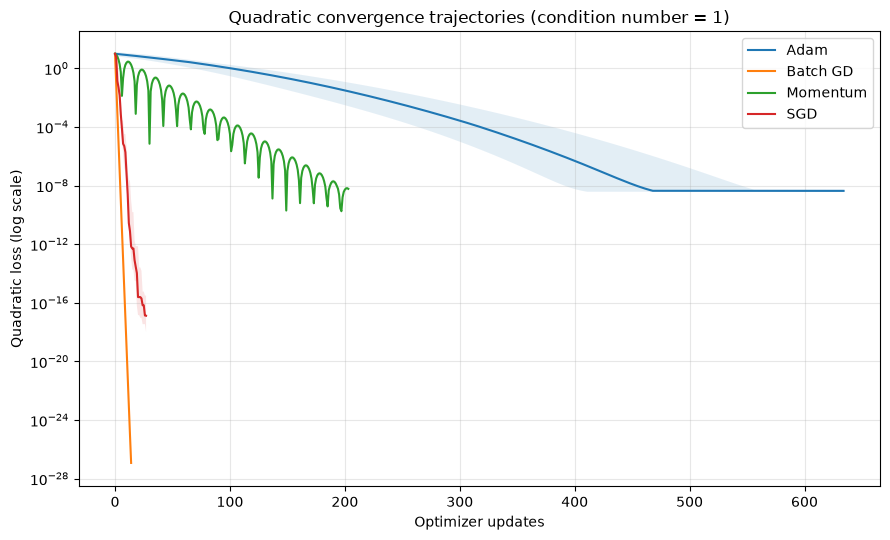

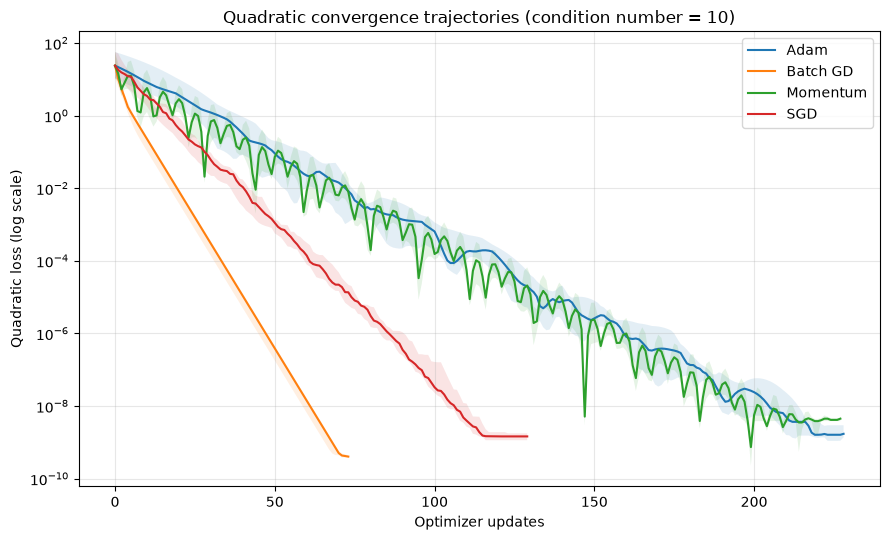

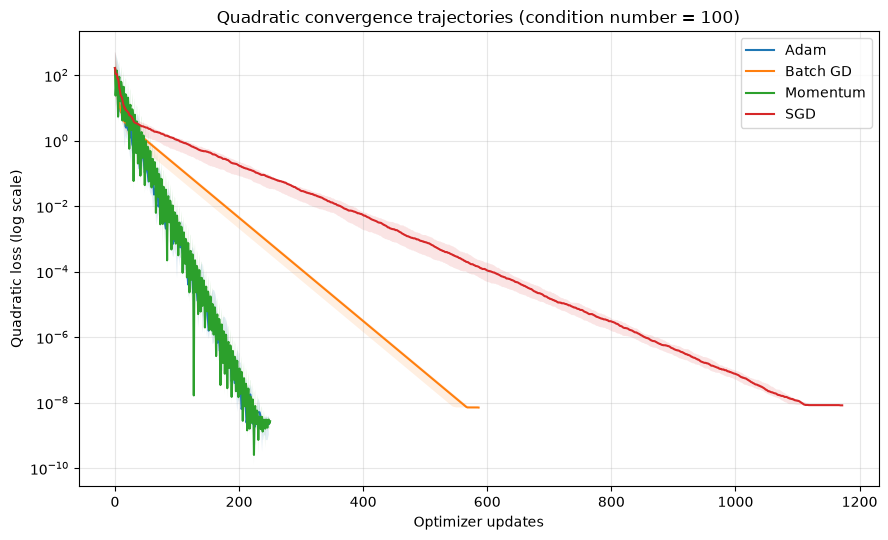

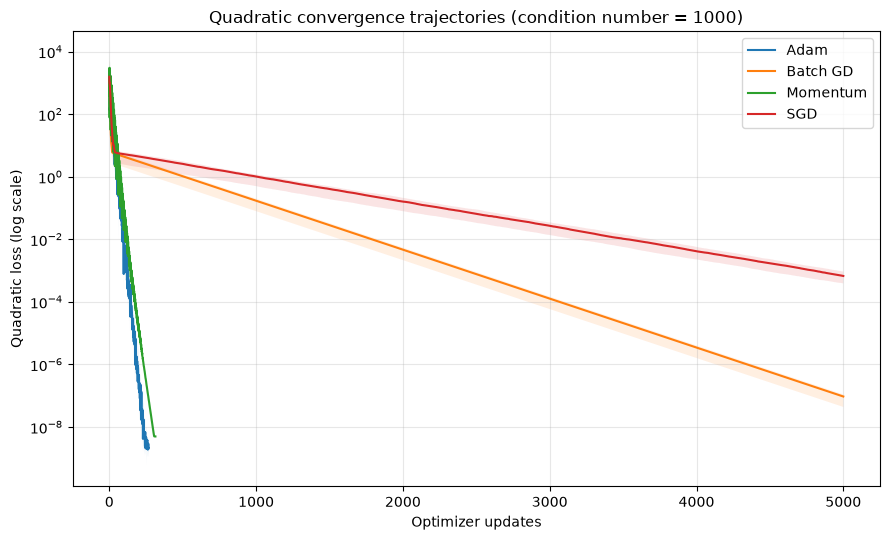

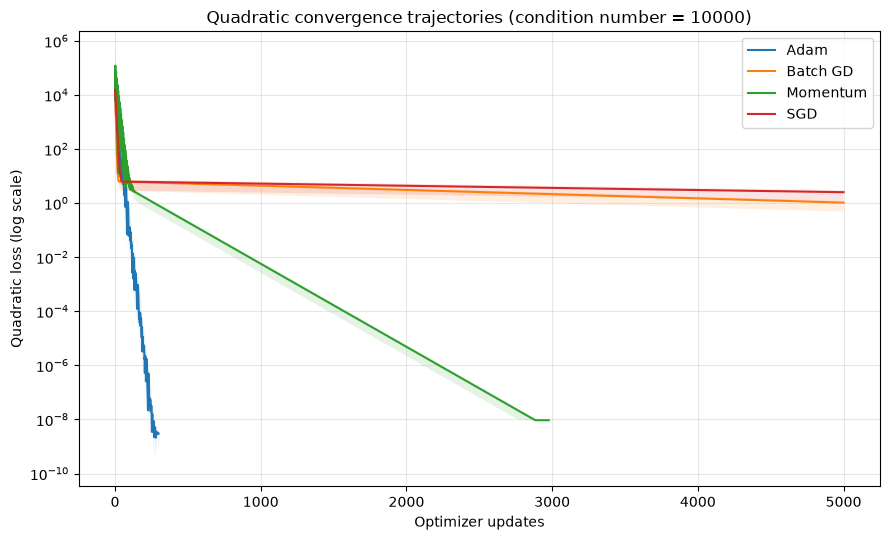

In [15]:
for kappa in QUADRATIC_CONFIG["condition_numbers"]:
    fig, ax = plt.subplots(figsize=(9, 5.5))
    for optimizer_name in QUADRATIC_OPTIMIZERS:
        histories = [
            np.asarray(
                quadratic_evaluation_histories[(kappa, optimizer_name, seed)],
                dtype=float,
            )
            for seed in QUADRATIC_CONFIG["evaluation_seeds"]
        ]
        max_length = max(map(len, histories))
        aligned = np.empty((len(histories), max_length), dtype=float)
        for row, history in enumerate(histories):
            aligned[row, :len(history)] = history
            aligned[row, len(history):] = history[-1]

        median = np.median(aligned, axis=0)
        lower = np.percentile(aligned, 25, axis=0)
        upper = np.percentile(aligned, 75, axis=0)
        updates = np.arange(max_length)
        # A small plotting floor avoids log(0) if floating-point underflow occurs.
        floor = np.finfo(float).tiny
        ax.plot(updates, np.maximum(median, floor), label=optimizer_name)
        ax.fill_between(
            updates,
            np.maximum(lower, floor),
            np.maximum(upper, floor),
            alpha=0.12,
        )

    ax.set_yscale("log")
    ax.set_xlabel("Optimizer updates")
    ax.set_ylabel("Quadratic loss (log scale)")
    ax.set_title(f"Quadratic convergence trajectories (condition number = {kappa})")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        FIGURES_PATH / f"quadratic_convergence_kappa_{kappa}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()

In [16]:
def summarize_quadratic_group(group):
    converged_group = group[group["Converged"]]
    return pd.Series(
        {
            "Runs": len(group),
            "Converged Runs": len(converged_group),
            "Convergence Rate": group["Converged"].mean(),
            "Median Updates to Convergence": (
                converged_group["Convergence Update"].median()
                if len(converged_group) else np.nan
            ),
            "Mean Updates to Convergence": (
                converged_group["Convergence Update"].mean()
                if len(converged_group) else np.nan
            ),
            "Median Updates Used": group["Parameter Updates"].median(),
            "Median Final Loss": group["Final Loss"].median(),
            "Mean Final Loss": group["Final Loss"].mean(),
        }
    )

quadratic_summary = (
    quadratic_evaluation_df.groupby(["Condition Number", "Optimizer"])
    .apply(summarize_quadratic_group, include_groups=False)
    .reset_index()
)
display(quadratic_summary.round(8))
quadratic_summary.to_csv(TABLES_PATH / "quadratic_convergence_summary.csv", index=False)

,Condition Number,Optimizer,Runs,Converged Runs,Convergence Rate,Median Updates to Convergence,Mean Updates to Convergence,Median Updates Used,Median Final Loss,Mean Final Loss
0,1,Adam,10.0,10.0,1.0,447.5,419.2,447.5,0.000000e+00,0.000000e+00
1,1,Batch GD,10.0,10.0,1.0,14.0,13.9,14.0,0.000000e+00,0.000000e+00
2,1,Momentum,10.0,10.0,1.0,202.5,196.5,202.5,1.000000e-08,1.000000e-08
3,1,SGD,10.0,10.0,1.0,20.0,21.1,20.0,0.000000e+00,0.000000e+00
4,10,Adam,10.0,10.0,1.0,214.0,210.4,214.0,0.000000e+00,0.000000e+00
5,10,Batch GD,10.0,10.0,1.0,70.5,67.8,70.5,0.000000e+00,0.000000e+00
6,10,Momentum,10.0,10.0,1.0,209.5,210.0,209.5,0.000000e+00,0.000000e+00
7,10,SGD,10.0,10.0,1.0,116.0,115.4,116.0,0.000000e+00,0.000000e+00
8,100,Adam,10.0,10.0,1.0,229.5,228.0,229.5,0.000000e+00,0.000000e+00
9,100,Batch GD,10.0,10.0,1.0,567.5,541.6,567.5,1.000000e-08,1.000000e-08


In [17]:
# Compare convergence speed with each optimizer's condition-number-1 baseline.
baseline = quadratic_summary[
    quadratic_summary["Condition Number"] == 1
][["Optimizer", "Median Updates to Convergence"]].rename(
    columns={"Median Updates to Convergence": "Baseline Median Updates"}
)
update_scaling_df = quadratic_summary.merge(baseline, on="Optimizer", how="left")
update_scaling_df["Convergence Update Ratio"] = (
    update_scaling_df["Median Updates to Convergence"] /
    update_scaling_df["Baseline Median Updates"]
)
display(
    update_scaling_df[
        [
            "Condition Number", "Optimizer", "Converged Runs",
            "Convergence Rate", "Median Updates to Convergence",
            "Baseline Median Updates", "Convergence Update Ratio",
            "Median Updates Used", "Median Final Loss",
        ]
    ].round(4)
)
update_scaling_df.to_csv(TABLES_PATH / "quadratic_update_scaling.csv", index=False)

,Condition Number,Optimizer,Converged Runs,Convergence Rate,Median Updates to Convergence,Baseline Median Updates,Convergence Update Ratio,Median Updates Used,Median Final Loss
0,1,Adam,10.0,1.0,447.5,447.5,1.0000,447.5,0.0000
1,1,Batch GD,10.0,1.0,14.0,14.0,1.0000,14.0,0.0000
2,1,Momentum,10.0,1.0,202.5,202.5,1.0000,202.5,0.0000
3,1,SGD,10.0,1.0,20.0,20.0,1.0000,20.0,0.0000
4,10,Adam,10.0,1.0,214.0,447.5,0.4782,214.0,0.0000
5,10,Batch GD,10.0,1.0,70.5,14.0,5.0357,70.5,0.0000
6,10,Momentum,10.0,1.0,209.5,202.5,1.0346,209.5,0.0000
7,10,SGD,10.0,1.0,116.0,20.0,5.8000,116.0,0.0000
8,100,Adam,10.0,1.0,229.5,447.5,0.5128,229.5,0.0000
9,100,Batch GD,10.0,1.0,567.5,14.0,40.5357,567.5,0.0000


### B6. Interpretation and limitations

- Report convergence rates across the ten independent evaluation seeds.
- Report median/mean updates to convergence only for runs that met the criterion; show the number of converged runs alongside these summaries.
- Report final loss for all runs, including stable non-converged runs.
- A selected learning rate at a grid boundary indicates that the best observed candidate may lie outside the tested range. Describe it as the best among tested rates, not a proven optimum.
- Equal update budgets are not equal computational budgets because full-gradient updates process both coordinates whereas stochastic coordinate updates process one.
- The diagonal quadratic is a controlled mathematical example. Adam's coordinate-wise scaling may be especially well matched to this objective; these results should not be generalized to every ill-conditioned problem.
- The real-data and quadratic experiments answer complementary questions and should be discussed separately before drawing an overall conclusion.
